## ML1 – Method decision (before fitting)

**Main model:** Truncated SVD. **Comparison (ML5):** PCA (arpack), same k, same matrix.

**Why SVD**
1. **Sparse data:** A is 5,473 × 3,687, 413,927 non-zeros (97.95% sparse, 4.99 MB).
   SVD uses it as is. PCA centres columns, turning every zero into a negative
   value, so the maths runs on a dense matrix (161 MB if built).
2. **Fits the job:** one fit gives product factors (Vᵀ) for "also bought"
   similarity and customer factors (U·S) for scoring.
3. **Meaning:** uncentred, component 1 = overall volume/popularity. This keeps the
   popularity signal, which matters in Q4. Risk: suggestions drift towards best sellers.

**Prediction:** SVD beats PCA on hit@10, fit time and peak memory; PCA gives the
cleaner customer map.

**k rule (R2):** k is chosen from the reconstruction-error curve plus storage/speed,
before any test hit rate is computed. Test hit@10 is then reported for all
k ∈ {10, 20, 50, 100, 200} as sensitivity only.

**Would change my mind if:** PCA beats SVD on hit@10 by > 3% points at similar
cost, or SVD fails to beat the best-seller baseline.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.sparse as sp
import time
from sklearn.decomposition import TruncatedSVD

# load the A matrix, customer index, product index and test pair matrix from the processed files

SEED = 42

# Find the project root (same function as the DE notebook)
def project_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / ".git").exists():
            return p
    raise FileNotFoundError("No .git folder found above " + str(start))

ROOT = project_root()
PROCESSED = ROOT / "data" / "processed"
REPORTS = ROOT / "reports"
print("Project root:", ROOT)

#  Load the training matrix
A = sp.load_npz(PROCESSED / "A_train.npz")
print("Type:", type(A))
print("Shape:", A.shape, "| non-zeros:", A.nnz)

customer_list = pd.read_parquet(PROCESSED / "customer_index.parquet")["Customer ID"].tolist()
product_list = pd.read_parquet(PROCESSED / "product_index.parquet")["StockCode"].tolist()
test_pairs_matrix = pd.read_parquet(PROCESSED / "test_pairs_matrix.parquet")
print("Customers:", len(customer_list), "| Products:", len(product_list))
print("Test pairs:", len(test_pairs_matrix),
      "| Eval customers:", test_pairs_matrix["Customer ID"].nunique())


Project root: /Users/muhammadsaadmalik/MS AI/Fall2026/Linear Algebra/Mini Projects/customers-like-you
Type: <class 'scipy.sparse._csr.csr_matrix'>
Shape: (5473, 3687) | non-zeros: 413927
Customers: 5473 | Products: 3687
Test pairs: 44727 | Eval customers: 1913


In [ ]:
############## ML1. ###################
squared_forbenius_norm = round((A.data ** 2).sum(), 2)
print("Squared Frobenius Norm:", squared_forbenius_norm)

Squared Frobenius Norm: 2390381.95


In [15]:
def fit_svd(A, k, squared_forbenius_norm, seed=42):
    """Fit Truncated SVD with k components and return the key numbers."""
    start_perf = time.perf_counter()

    svd_model = TruncatedSVD(n_components=k, random_state=seed)
    svd_model.fit(A)

    end_perf = time.perf_counter()
    execution_time = end_perf - start_perf

    energy_kept = (svd_model.singular_values_ ** 2).sum()
    rel_error = np.sqrt(max(0.0, 1 - energy_kept / squared_forbenius_norm))
    factors_mb = (A.shape[0] + A.shape[1]) * k * 8 / 1000000

    return {"k": k, "execution_time (s)": execution_time, "relative_error": rel_error,
            "factors_mb": factors_mb, "svd_model": svd_model}

In [22]:
k_list = [10, 20, 50, 100, 200]
warm_up = fit_svd(A, 1, squared_forbenius_norm, seed=SEED)

models = {}
rows = []

for k in k_list:
    result = fit_svd(A, k, squared_forbenius_norm, seed=SEED)
    models[k] = result.pop("svd_model")                         # model kept separately, will use later on
    rows.append(result)
curve = pd.DataFrame(rows)
print(curve)

     k  execution_time (s)  relative_error  factors_mb
0   10            0.035715        0.875917      0.7328
1   20            0.046210        0.845705      1.4656
2   50            0.072906        0.789583      3.6640
3  100            0.133954        0.727785      7.3280
4  200            0.260571        0.639466     14.6560


In [20]:
curve["gain_per_component"] = -curve["relative_error"].diff() / curve["k"].diff()

sparse_mb = (A.data.nbytes + A.indices.nbytes + A.indptr.nbytes) / 1e6
breakeven_k = sparse_mb * 1e6 / ((A.shape[0] + A.shape[1]) * 8)

print(f"Break-even point: {breakeven_k:.2f} components")


Break-even point: 68.08 components


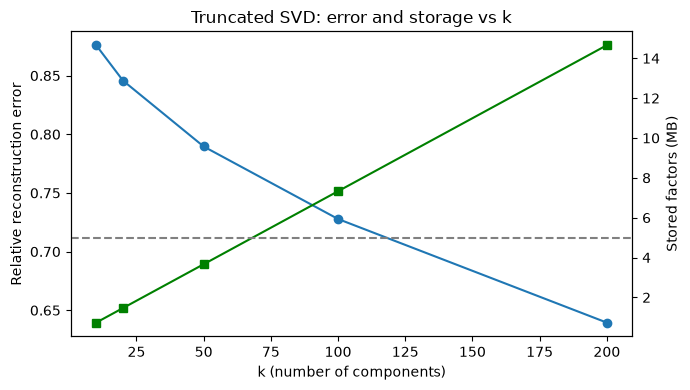

In [51]:
import matplotlib.pyplot as plt

FIGURES = REPORTS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.plot(curve["k"], curve["relative_error"], marker="o", label="Relative error")
ax1.set_xlabel("k (number of components)")
ax1.set_ylabel("Relative reconstruction error")

ax2 = ax1.twinx()                                   # second y-axis, same x
ax2.plot(curve["k"], curve["factors_mb"], marker="s", color="green", label="Factor size (MB)")
ax2.axhline(4.99, linestyle="--", color="grey")     # sparse matrix size
ax2.set_ylabel("Stored factors (MB)")

ax1.set_title("Truncated SVD: error and storage vs k")
fig.tight_layout()
fig.savefig(FIGURES / "ml2_error_vs_k.png", dpi=150)   # saving kept outside functions
plt.show()

In [43]:
############## ML3. ###################
from sklearn.preprocessing import normalize

print(models[50].components_.shape)
# print(models[50].components_)
#transpose
model50_transposed = models[50].components_.transpose()
print(model50_transposed.shape)
#normalise
P = normalize(model50_transposed, axis=1) #normalised_model50_transposed
#print(P)
row_lengths = np.linalg.norm(P, axis=1)
print("Row lengths min/max:", row_lengths.min(), row_lengths.max())
# assert P.shape == (len(product_list), 50)
# assert np.allclose(row_lengths, 1.0)


(50, 3687)
(3687, 50)
Row lengths min/max: 0.9999999999999994 1.0000000000000007


In [47]:
def similar_products(product_index, P, n=10):
    """Return the n products most similar to product (cosine similarity)."""
    scores = P @ P[product_index]                 # Step 1: similarity of every product to j
    scores[product_index] = -np.inf               # Step 2: never recommend itself
    top = np.argsort(-scores)[:n]                 # Step 3: get the indices of the top n scores
    return top

In [ ]:
similar_products_dict = {}
for i in range(len(product_list)):
    similar = similar_products(i, P, n=10)
    similar_products_dict[product_list[i]] = [product_list[j] for j in similar]

similar_products_df = pd.DataFrame(similar_products_dict, index=range(1, 11))
similar_products_df.index.name = "rank"

print(similar_products_df.shape)                # (10, 3687)
print(similar_products_df.iloc[:, :3])          # first 3 products only, top 10 recommendations
assert similar_products_df.shape == (10, len(product_list))

similar_products_df.to_csv(REPORTS / "also_bought_k50.csv")
print("File size MB:", round((REPORTS / "also_bought_k50.csv").stat().st_size / 1e6, 2))

(10, 3687)
       10002   10080   10120
rank                        
1      21789   22609   90087
2      21708   20716  90120D
3      21731  16169E  37489D
4      21441   16236  37489B
5      21915  16161G   90086
6      21788   79320  37489C
7     84796B   23321  37489A
8     62096B   21374   84548
9      21316   22610  16020C
10     23084   21213  35838A
File size MB: 0.25


In [63]:
def score_customer(i, A, P):
    """Score all products for the customer in row i of A (bought items masked)."""
    a = A[i]                                          # Step 1: what they bought
    customer_vec = a @ P                              # Step 2: customer arrow (50 numbers)
    scores = customer_vec @ P.T                       # Step 3: score every product
    scores = np.asarray(scores).ravel()               # Step 4: make it a flat list
    scores[a.indices] = -np.inf                       # Step 5: hide what they already bought
    return scores

def recommend(i, A, P, n=10):
    """Return the indices of the n best new products for customer row i."""
    scores = score_customer(i, A, P)
    top = np.argsort(-scores)[:n]                     # highest scores first
    return top

In [67]:
# checking on a random customer
i = 6
train = pd.read_parquet(PROCESSED / "train.parquet")
descriptions = train.groupby("StockCode")["Description"].first()
recs = recommend(i, A, P)

print(f"Customer #{i} bought {A[i].nnz} products, for example:")
for j in A[i].indices[:5]:
    print("   ", descriptions[product_list[j]])

print(f"Top 10 recommendations for customer #{i}:")
for j in recs:
    print("   ", descriptions[product_list[j]])

# Checks
assert len(recs) == 10                                # exactly 10
assert not set(recs) & set(A[i].indices)              # nothing already bought

Customer #6 bought 57 products, for example:
    SET/10 RED SPOTTY PARTY CANDLES
    SET/10 PINK SPOTTY PARTY CANDLES
    COOK WITH WINE METAL SIGN 
    GIN + TONIC DIET METAL SIGN
    PLEASE ONE PERSON  METAL SIGN
Top 10 recommendations for customer #6:
    RECIPE BOX PANTRY YELLOW DESIGN
    CERAMIC BOWL WITH STRAWBERRY DESIGN
    JAM MAKING SET WITH JARS
    LADIES & GENTLEMEN METAL SIGN
    PANTRY ROLLING PIN
    SET 2 PANTRY DESIGN TEA TOWELS
    CERAMIC PLATE STRAWBERRY DESIGN
    JAM MAKING SET PRINTED
    CERAMIC CHERRY CAKE MONEY BANK
    TOAST ITS - HAPPY BIRTHDAY


In [69]:
##### verification of shapes and sizes
a = A[0]
print("A:", A.shape)                       # (5473, 3687)
print("a = A[0]:", a.shape)                # (1, 3687)
print("P:", P.shape)                       # (3687, 50)
customer_vec = a @ P
print("a @ P:", customer_vec.shape)        # (1, 50)
scores = customer_vec @ P.T
print("(a @ P) @ P.T:", scores.shape)      # (1, 3687)

A: (5473, 3687)
a = A[0]: (1, 3687)
P: (3687, 50)
a @ P: (1, 50)
(a @ P) @ P.T: (1, 3687)


In [88]:
########################### ML4 ##############################
K_CHOSEN = 50

# ===== Chunk 1: answer key =====
def build_answer_key(test_pairs_matrix, customer_list, product_list):
    """For each test customer, find which products they bought in the test period.

    Returns a dictionary: customer row number -> set of product column numbers.
    """
    # Step 1: lookup tables from ID to position in the matrix
    customer_to_row = {}
    for row_number, customer_id in enumerate(customer_list):
        customer_to_row[customer_id] = row_number

    product_to_col = {}
    for col_number, stock_code in enumerate(product_list):
        product_to_col[stock_code] = col_number

    # Step 2: go through the test pairs one by one and file them per customer
    answer_key = {}
    for customer_id, stock_code in zip(test_pairs_matrix["Customer ID"],
                                       test_pairs_matrix["StockCode"]):
        row = customer_to_row[customer_id]      # KeyError here = pair not in matrix
        col = product_to_col[stock_code]

        if row not in answer_key:               # first time we see this customer
            answer_key[row] = set()
        answer_key[row].add(col)

    return answer_key


answer_key = build_answer_key(test_pairs_matrix, customer_list, product_list)

# Step 3: count what we got
n_customers = len(answer_key)
n_pairs = 0
for products in answer_key.values():
    n_pairs = n_pairs + len(products)

print("Evaluation customers:", n_customers)
print("Held-out pairs:", n_pairs)

# Step 4: checks against the DE numbers
assert n_customers == 1913
assert n_pairs == len(test_pairs_matrix)       # 44,727

Evaluation customers: 1913
Held-out pairs: 44727


In [89]:
# ===== Chunk 2: hit rate =====
def hit_rate(answer_key, top_n):
    """Share of evaluation customers with at least one held-out product in their top-n."""
    hits = 0
    for row, held_out_products in answer_key.items():
        recommended_products = set(top_n[row])               # this customer's top-n
        common = recommended_products & held_out_products    # products in both sets
        if len(common) > 0:
            hits = hits + 1
    return hits / len(answer_key)

In [ ]:
# ===== Chunk 3: model recommendations for all customers =====
def product_vectors(model):
    """One row per product, each row scaled to length 1."""
    vectors = model.components_.T
    vectors = normalize(vectors, axis=1)
    return vectors

def score_all_customers(A, P, n=10, batch_size=500):
    """Top-n new products for every customer, 500 customers at a time."""
    n_customers = A.shape[0]
    top_n = np.zeros((n_customers, n), dtype=int)

    for start in range(0, n_customers, batch_size):
        stop = min(start + batch_size, n_customers)

        # Step 1: take a block of customers
        A_batch = A[start:stop]

        # Step 2: score every product for every customer in the block
        customer_vectors = A_batch @ P             # (batch, k)
        scores = customer_vectors @ P.T            # (batch, products)

        # Step 3: hide products each customer already bought
        bought = A_batch.nonzero()                 # (row numbers, column numbers)
        bought_rows = bought[0]
        bought_cols = bought[1]
        scores[bought_rows, bought_cols] = -np.inf

        # Step 4: keep the n highest scores in each row
        order = np.argsort(-scores, axis=1)
        top_n[start:stop] = order[:, :n]

    return top_n

P = product_vectors(models[K_CHOSEN])

start_time = time.perf_counter()
model_top10 = score_all_customers(A, P, n=10)
score_seconds = time.perf_counter() - start_time
print("Scored all customers in", round(score_seconds, 2), "seconds")
print("Recommendation table shape:", model_top10.shape)

# Check: batch version gives the same answer as the ML3 function
for row in [0, 100, 2000]:
    one_by_one = recommend(row, A, P, n=10)
    assert (model_top10[row] == one_by_one).all(), f"mismatch for customer #{row}"
print("Batch scoring matches recommend()")

model_hit_rate = hit_rate(answer_key, model_top10)
print("Model hit@10:", round(model_hit_rate, 4))

Scored all customers in 0.77 s; shape (5473, 10)
Batch scoring matches recommend()
Model hit@10: 0.2148


In [ ]:
# ===== Chunk 4: best-seller baseline =====
def best_seller_top_n(A, n=10):
    """For every customer: the n most popular products they have not bought yet."""
    # Step 1: how many customers bought each product (training data only)
    customers_per_product = A.getnnz(axis=0)

    # Step 2: product numbers from most to least popular
    popularity_order = np.argsort(-customers_per_product)

    # Step 3: walk down the list for each customer, skipping what they own
    n_customers = A.shape[0]
    top_n = np.zeros((n_customers, n), dtype=int)
    for row in range(n_customers):
        already_bought = set(A[row].indices)
        picks = []
        for product in popularity_order:
            if product not in already_bought:
                picks.append(product)
            if len(picks) == n:
                break
        top_n[row] = picks

    return top_n, popularity_order

baseline_top10, popularity_order = best_seller_top_n(A, n=10)
baseline_hit_rate = hit_rate(answer_key, baseline_top10)
print("Baseline hit@10:", round(baseline_hit_rate, 4))

for row in [0, 100, 2000]:
    overlap = set(baseline_top10[row]) & set(A[row].indices)
    assert len(overlap) == 0, f"baseline recommends a bought product to customer #{row}"

Baseline hit@10: 0.2687


In [ ]:
# ===== Chunk 5: results table =====
gap_points = (model_hit_rate - baseline_hit_rate) * 100

results = pd.DataFrame({
    "method": [f"Truncated SVD (k={K_CHOSEN})", "Best-seller baseline"],
    "hit_rate_at_10_%": [round(model_hit_rate * 100, 1), round(baseline_hit_rate * 100, 1)],
})
print(results.to_string(index=False))

if gap_points > 3:
    verdict = "model clearly beats the baseline"
elif gap_points < -3:
    verdict = "model clearly LOSES to the baseline"
else:
    verdict = "within noise (±3 points), no clear winner"
print(f"Gap: {gap_points:+.1f} points -> {verdict}")

results.to_csv(REPORTS / "ml4_results.csv", index=False)

              method  hit_rate_at_10  hit_rate_%
Truncated SVD (k=50)        0.214846        21.5
Best-seller baseline        0.268688        26.9
Gap -5.4 points: model clearly LOSES to baseline


In [ ]:
# ===== Chunk 6: nightly job timing =====
def build_also_bought(P, n=10):
    """Top-n most similar products for every product."""
    similarity = P @ P.T                       # products x products
    np.fill_diagonal(similarity, -np.inf)      # a product is not its own suggestion
    order = np.argsort(-similarity, axis=1)
    return order[:, :n]

# Part 1: fit
start_time = time.perf_counter()
job_model = TruncatedSVD(n_components=K_CHOSEN, random_state=SEED).fit(A)
fit_seconds = time.perf_counter() - start_time

# Part 2: product pages table
start_time = time.perf_counter()
job_P = product_vectors(job_model)
job_also_bought = build_also_bought(job_P, n=10)
also_bought_seconds = time.perf_counter() - start_time

# Part 3: recommendations for every customer
start_time = time.perf_counter()
job_top10 = score_all_customers(A, job_P, n=10)
customer_seconds = time.perf_counter() - start_time

total_seconds = fit_seconds + also_bought_seconds + customer_seconds

timing = pd.DataFrame({
    "step": ["fit SVD", "also-bought table", "score all customers", "total"],
    "seconds": [round(fit_seconds, 3), round(also_bought_seconds, 3),
                round(customer_seconds, 3), round(total_seconds, 3)],
})
print(timing.to_string(index=False))
timing.to_csv(REPORTS / "ml4_nightly_timing.csv", index=False)

                       seconds
1_fit_svd                0.104
2_also_bought_table      0.539
3_score_all_customers    0.742
total                    1.384


In [ ]:
# ===== Chunk 7: hit rate for every k (report only) =====
sensitivity_rows = []
for k in models:
    P_k = product_vectors(models[k])
    top10_k = score_all_customers(A, P_k, n=10)
    hit_rate_k = hit_rate(answer_key, top10_k)
    sensitivity_rows.append({
        "k": k,
        "model_hit_rate_%": round(hit_rate_k * 100, 1),
        "baseline_hit_rate_%": round(baseline_hit_rate * 100, 1),
        "gap_points": round((hit_rate_k - baseline_hit_rate) * 100, 1),
    })
    print(f"k={k}: hit@10 = {hit_rate_k:.4f}")

sensitivity = pd.DataFrame(sensitivity_rows)
print(sensitivity.to_string(index=False))
sensitivity.to_csv(REPORTS / "ml4_sensitivity_k.csv", index=False)

  k  hit_rate_at_10  baseline  gap_points
 10          0.1479    0.2687    -12.0753
 20          0.1830    0.2687     -8.5729
 50          0.2148    0.2687     -5.3842
100          0.2269    0.2687     -4.1819
200          0.2159    0.2687     -5.2797
